# Customer Churn with Survival Analysis: When Will a Customer Leave?

A telecom company knows that about one in four customers in its books has left. The usual notebook trains a yes/no classifier on that flag. But most customers have **not left yet**, which does not mean they never will, and a customer who joined last month is not the same as one who stayed six years. Survival analysis answers the question the retention team actually asks: **how long will each customer stay, who is about to leave, and how much revenue is at risk?**

**Objectives**
1. What does "not churned yet" (censoring) do to simple averages?
2. When in the customer lifetime is the risk of leaving highest?
3. Which contracts, services and payment methods change that risk, and by how much?
4. Which model ranks customers best, and are its probabilities honest?
5. Who should the retention team call first, and what is that worth?

**Data** → [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM sample data) · 7,043 customers · tenure in months, churn flag, services, contract, charges

<!-- objective -->
## Objective

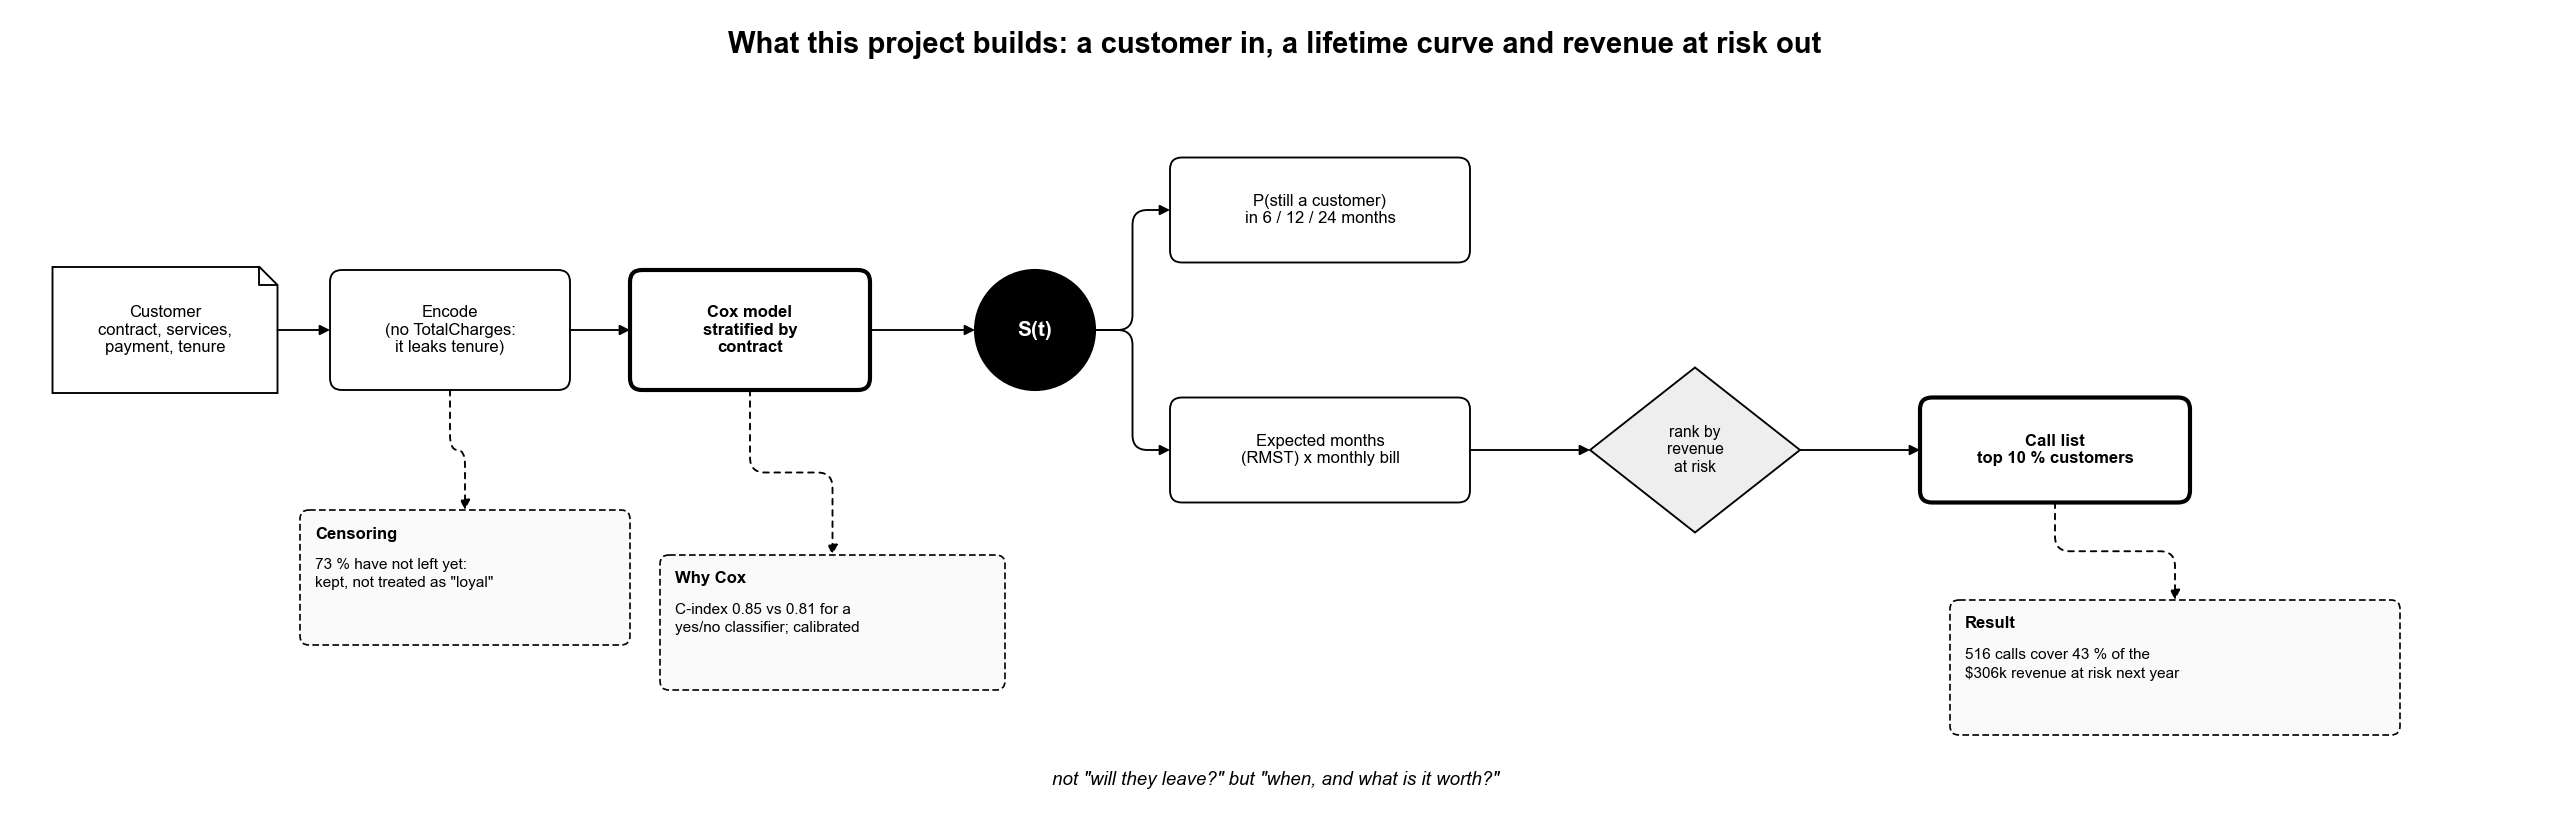

- **Problem** → a subscription business loses customers every month, and a yes/no churn model treats the 73 % who have not left *yet* as if they never will
- **Why this repo** → model *when* each customer is likely to leave (survival analysis), find what changes that timing, and turn each curve into expected months and revenue at risk
- **Real-world use** → a weekly retention call list ranked by money at stake, and a what-if view of contracts and support add-ons

# [1/13] Setup

Set every knob once in the top cell → nothing is written and no app is started unless you switch it on

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/10] DATA_DIR: folder searched recursively for the Telco CSV (falls back to /kaggle/input)
    Default = '/kaggle/input/datasets/blastchar/telco-customer-churn'
[2/10] WORK_DIR: folder for figures and the model file
    Default = '/kaggle/working'
[3/10] TEST_SIZE: share of customers kept aside for the final scores
    Default = 0.2
[4/10] PENALIZER: L2 penalty of the Cox model (shrinks unstable coefficients)
    Default = 0.01
    For example:
        PENALIZER = 0.1
[5/10] HORIZONS: months at which probabilities are checked and reported
    Default = [6, 12, 24]
[6/10] RMST_MONTHS: window for "expected months as a customer" (restricted mean survival time)
    Default = 24
[7/10] CALL_SHARE: share of customers the retention team can call
    Default = 0.10
[8/10] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
[9/10] SAVE_MODEL: write the Cox model for the app to WORK_DIR/churn_cox.joblib
    Default = False
[10/10] LAUNCH_APP: start the Gradio churn explorer at the end (public link on Kaggle)
    Default = False
"""
DATA_DIR     = '/kaggle/input/datasets/blastchar/telco-customer-churn'
WORK_DIR     = '/kaggle/working'
TEST_SIZE    = 0.2
PENALIZER    = 0.01
HORIZONS     = [6, 12, 24]
RMST_MONTHS  = 24
CALL_SHARE   = 0.10
SAVE_FIGURES = False
SAVE_MODEL   = False
LAUNCH_APP   = False

SEED         = 42
PAD          = 36
MODEL_FILE   = f'{WORK_DIR}/churn_cox.joblib'
PALETTE      = {'main': 'black', 'flag': 'red', 'soft': 'grey'}

In [ ]:
%pip install -q lifelines
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from lifelines import CoxPHFitter, KaplanMeierFitter, NelsonAalenFitter, WeibullAFTFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, proportional_hazard_test
from lifelines.utils import concordance_index
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
ASSETS = Path(WORK_DIR) / 'assets'
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_telco_csv(*roots):
    """First CSV under the roots whose header has tenure, Churn and Contract."""
    import csv
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        for f in sorted(root.rglob('*.csv')):
            with open(f, newline='', encoding='utf-8', errors='ignore') as fh:
                header = next(csv.reader(fh), [])
            if {'tenure', 'Churn', 'Contract'} <= set(header):
                return f
    raise FileNotFoundError('(!) No Telco churn CSV found. Add Input -> Datasets -> blastchar/telco-customer-churn')


ADDONS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']


def encode(df):
    """Customer table → numeric model inputs (same function is copied into app.py)."""
    yes = lambda s: (s == 'Yes').astype(int)
    out = pd.DataFrame(index=df.index)
    out['male'] = (df['gender'] == 'Male').astype(int)
    out['senior'] = df['SeniorCitizen'].astype(int)
    for col in ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'PaperlessBilling'] + ADDONS:
        out[col] = yes(df[col])
    out['fiber_optic'] = (df['InternetService'] == 'Fiber optic').astype(int)
    out['no_internet'] = (df['InternetService'] == 'No').astype(int)
    out['one_year_contract'] = (df['Contract'] == 'One year').astype(int)
    out['two_year_contract'] = (df['Contract'] == 'Two year').astype(int)
    out['pay_electronic_check'] = (df['PaymentMethod'] == 'Electronic check').astype(int)
    out['pay_mailed_check'] = (df['PaymentMethod'] == 'Mailed check').astype(int)
    out['pay_credit_card'] = (df['PaymentMethod'] == 'Credit card (automatic)').astype(int)
    out['monthly_charges_10usd'] = df['MonthlyCharges'] / 10
    return out


def km_at(times, events, t):
    return float(KaplanMeierFitter().fit(times, events).survival_function_at_times(t).iloc[0])

# [2/13] Data

Load the customers → one row per customer: how long they have been with the company, whether they left, and what they pay for

In [ ]:
raw = pd.read_csv(find_telco_csv(DATA_DIR, '/kaggle/input'))
show_block('Outputs', {'customers': f'{len(raw):,}', 'columns': raw.shape[1],
                       'churned (left)': f'{(raw["Churn"] == "Yes").mean():.1%}'})

In [ ]:
display(raw.head(3).T)

# [3/13] Data health

Fix the gaps and find columns that secretly contain the answer → clean table, one leak removed

**Question:** Is the table ready, and does any column give the duration away?

$$\text{TotalCharges} \approx \text{MonthlyCharges} \times \text{tenure}$$
- `TotalCharges` is a running bill: it grows with every month the customer stays
- a model given `TotalCharges` and `MonthlyCharges` can recompute the tenure it is supposed to predict → **leakage**
- Analogy → predicting how long a guest stayed at a hotel from the final bill

**Answer:** nearly ready, with one leak.
- 11 blank `TotalCharges` belong to customers with tenure 0 (joined this month) → dropped, 7,032 kept
- `TotalCharges` / (monthly × tenure) has median 1.000 and correlates 0.83 with tenure → left out of every model

In [ ]:
df = raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
blank_total = df['TotalCharges'].isna()
tenure_zero = df['tenure'] == 0
ratio = df['TotalCharges'] / (df['MonthlyCharges'] * df['tenure'])
df = df[~tenure_zero].copy()
df['churn'] = (df['Churn'] == 'Yes').astype(int)
X_all = encode(df)

In [ ]:
show_block('Outputs', {
    'blank TotalCharges': int(blank_total.sum()),
    'of which tenure = 0': int((blank_total & tenure_zero).sum()),
    'customers kept (tenure >= 1 month)': f'{len(df):,}',
    'TotalCharges / (Monthly x tenure), median': f'{ratio.median():.3f}',
    'correlation TotalCharges vs tenure': f'{raw.assign(tc=pd.to_numeric(raw["TotalCharges"], errors="coerce"))[["tc", "tenure"]].corr().iloc[0, 1]:.3f}',
    'model inputs': X_all.shape[1]})

# [4/13] Why survival analysis?

Compare naive answers with the censoring-aware answer → the naive averages are badly wrong

**Question:** What is wrong with "average tenure" or "share who churned"?

- **censored** → a customer still with the company: we know they stayed *at least* `tenure` months, not how long they will stay
- the average tenure of churners ignores everyone who stayed; the churn share ignores *when* people left
- **Kaplan-Meier** uses both kinds of customers: at every month, the share of customers still at risk who leave
- Analogy → judging a marathon by the finishing times of runners who dropped out, ignoring those still running

**Answer:** both hide the 73 % who have not left yet.
- churners stayed 18.0 months on average, everyone 32.4, yet Kaplan-Meier says 59.3 % are still customers after 72 months
- "26.6 % churned" says nothing about when: 15.7 % are gone within the first year

In [ ]:
T, E = df['tenure'], df['churn']
km = KaplanMeierFitter().fit(T, E, label='all customers')
naive = pd.DataFrame({'value': {
    'share churned (flag)': f'{E.mean():.1%}',
    'mean tenure of churners (months)': f'{T[E == 1].mean():.1f}',
    'mean tenure of everyone (months)': f'{T.mean():.1f}',
    'Kaplan-Meier: still a customer after 12 months': f'{km_at(T, E, 12):.1%}',
    'Kaplan-Meier: still a customer after 72 months': f'{km_at(T, E, 72):.1%}',
    'censored customers (still active)': f'{1 - E.mean():.1%}'}})

In [ ]:
display(naive)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist([T[E == 0], T[E == 1]], bins=36, stacked=True, color=['lightgrey', 'red'], label=['still a customer (censored)', 'churned'])
ax.set(title='Tenure of every customer', xlabel='months with the company', ylabel='customers')
ax.legend()
save(fig, '01_tenure')
plt.show()

# [5/13] Kaplan-Meier: the customer lifetime curve

Estimate the share of customers still with the company after each month → the shape tells when people leave

**Question:** How long do customers stay?

$$\hat S(t) = \prod_{t_i \le t} \left(1 - \frac{d_i}{n_i}\right)$$
- $n_i$ → customers still at risk at month $t_i$, $d_i$ → customers who leave in that month
- each factor = the chance of surviving that month, given you reached it; censored customers leave the risk set without counting as churn
- Analogy → a staircase: every month you lose the share who walked out that month

**Answer:** most losses happen early; the median lifetime is never reached.
- still a customer: 88.5 % after 6 months, 84.3 % after 12, 78.9 % after 24
- monthly risk of leaving: 1.5 % in month 1, 0.4 % by month 36 → the first months decide

In [ ]:
naf = NelsonAalenFitter().fit(T, E)
hazard = naf.smoothed_hazard_(bandwidth=3)
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
km.plot_survival_function(ax=axes[0], color='black')
for h in HORIZONS:
    axes[0].axvline(h, color='grey', linestyle=':')
axes[0].set(title='Share of customers still with the company', xlabel='months', ylabel='S(t)', ylim=(0.5, 1.01))
axes[1].plot(hazard.index, hazard.iloc[:, 0], color='red')
axes[1].set(title='Monthly risk of leaving (smoothed hazard)', xlabel='months', ylabel='hazard per month')
fig.tight_layout()
save(fig, '02_kaplan_meier')
plt.show()

In [ ]:
show_block('Outputs', {**{f'S({h} months)': f'{km_at(T, E, h):.3f}' for h in HORIZONS},
                       'hazard month 1': f'{hazard.iloc[0, 0]:.3f}', 'hazard month 36': f'{hazard.loc[hazard.index >= 36].iloc[0, 0]:.3f}',
                       'median lifetime': 'not reached' if np.isinf(km.median_survival_time_) else f'{km.median_survival_time_:.0f} months'})

# [6/13] Who stays longer? Kaplan-Meier by group

Split the curve by contract, internet, payment and support → the log-rank test says whether a gap is real

**Question:** Which customer groups leave faster?

$$\chi^2_{\text{log-rank}} = \sum_{g} \frac{(O_g - E_g)^2}{E_g}$$
- $O_g$ → churns observed in group $g$; $E_g$ → churns expected if every group had the same curve
- large $\chi^2$ (tiny p) → the curves really differ
- Analogy → comparing how fast two queues empty, counting people still waiting

**Answer:** contract first, then payment, support and internet type (every log-rank p < 1e-100).
- still a customer after 24 months: month-to-month 58.6 % vs one-year 97.8 % vs two-year 100 %
- electronic check 62.4 % vs credit card 91.3 % · no tech support 65.3 % vs with support 91.7 % · fiber 70.2 % vs DSL 83.1 %

In [ ]:
GROUPS = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']
fig, axes = plt.subplots(1, 4, figsize=(26, 5.5), sharey=True)
logrank = {}
for ax, col in zip(axes, GROUPS):
    for i, (level, part) in enumerate(df.groupby(col)):
        KaplanMeierFitter().fit(part['tenure'], part['churn'], label=f'{level} (n={len(part):,})').plot_survival_function(
            ax=ax, ci_show=False, color=['black', 'red', 'grey', '#808080'][i % 4], linestyle=['-', '-', '--', ':'][i % 4])
    test = multivariate_logrank_test(df['tenure'], df[col], df['churn'])
    logrank[col] = {'chi-square': test.test_statistic, 'p-value': test.p_value,
                    **{f'S(24) {lvl}': round(km_at(p['tenure'], p['churn'], 24), 3) for lvl, p in df.groupby(col)}}
    ax.set(title=f'{col} (log-rank p = {test.p_value:.1e})', xlabel='months', ylim=(0, 1.02))
    ax.legend(fontsize=8)
fig.tight_layout()
save(fig, '03_km_groups')
plt.show()

In [ ]:
display(pd.DataFrame(logrank).T)

# [7/13] Cox model: what changes the risk, and by how much?

Fit a Cox proportional-hazards model on the training customers → one hazard ratio per factor, all others held equal

**Question:** By how much does each factor raise or cut the risk of leaving?

$$h(t \mid x) = h_0(t)\, \exp(\beta_1 x_1 + \dots + \beta_p x_p)$$
- $h_0(t)$ → the baseline monthly risk curve, shared by everyone; $\exp(\beta_j)$ → **hazard ratio**: 0.5 = half the risk, 2 = double, holding everything else fixed
- fitted on 80 % of customers; L2 penalty `PENALIZER` keeps correlated inputs (charges vs services) stable
- Analogy → one road with a speed limit for everyone; each habit multiplies your personal accident risk

**Answer:** the contract dwarfs everything else.
- two-year contract → hazard ratio 0.08 (12× less risk), one-year → 0.22; online backup, security and tech support each → about 0.5-0.65
- electronic check → 1.89, mailed check → 1.77, fiber → 1.41; monthly charge itself → 1.03 (not significant once services are known)

In [ ]:
train_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, stratify=df['churn'], random_state=SEED)
train = X_all.loc[train_idx].assign(tenure=T.loc[train_idx], churn=E.loc[train_idx])
test = X_all.loc[test_idx].assign(tenure=T.loc[test_idx], churn=E.loc[test_idx])
FEATURES = list(X_all.columns)

cph = CoxPHFitter(penalizer=PENALIZER).fit(train, duration_col='tenure', event_col='churn')
hr = cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']].rename(
    columns={'exp(coef)': 'hazard ratio', 'exp(coef) lower 95%': 'low 95%', 'exp(coef) upper 95%': 'high 95%'}).sort_values('hazard ratio')

In [ ]:
display(hr.round(3))
fig, ax = plt.subplots(figsize=(10, 8))
ax.errorbar(hr['hazard ratio'], hr.index, xerr=[hr['hazard ratio'] - hr['low 95%'], hr['high 95%'] - hr['hazard ratio']],
            fmt='o', color='black', ecolor='grey', capsize=3)
ax.axvline(1, color='red', linestyle='--')
ax.set_xscale('log')
ax.set(title='Hazard ratios (log scale): left of the red line = stays longer', xlabel='hazard ratio')
save(fig, '04_hazard_ratios')
plt.show()

# [8/13] Checking the Cox assumption

Test whether each hazard ratio stays constant over the customer lifetime → where it does not, the ratio is an average

**Question:** Is "one ratio for the whole lifetime" true?

- **proportional hazards** → the effect of a factor is the same in month 2 and month 60
- the test correlates each factor's residuals with time (rank-transformed); small p → the effect changes over time
- a violation does not break the ranking, but the hazard ratio becomes an average over the lifetime; stratifying on the factor gives it its own baseline curve
- Analogy → a seatbelt rule that matters more on the motorway than in the car park

**Answer:** not for everything: 5 factors change over time (p < 0.01), led by the one-year contract.
- stratifying by contract (each contract gets its own baseline curve) keeps the ranking (C-index 0.852 both)
- and fixes long-tenure probabilities: month-to-month customers leaving between month 60 and 72 → stratified 0.51 vs observed 0.57, plain Cox 0.75
- → the stratified model is used for the curves, the call list and the app

In [ ]:
ph = proportional_hazard_test(cph, train, time_transform='rank').summary[['test_statistic', 'p']].sort_values('p')
strat_cols = ['one_year_contract', 'two_year_contract']
train_s = train.assign(contract=train['one_year_contract'] + 2 * train['two_year_contract']).drop(columns=strat_cols)
test_s = test.assign(contract=test['one_year_contract'] + 2 * test['two_year_contract']).drop(columns=strat_cols)
cph_strat = CoxPHFitter(penalizer=PENALIZER).fit(train_s, duration_col='tenure', event_col='churn', strata=['contract'])
STRAT_INPUTS = list(train_s.columns.drop(['tenure', 'churn']))


def to_strat(X):
    """Contract dummies → one 'contract' stratum column (0 month-to-month, 1 one year, 2 two year)."""
    return X.assign(contract=X['one_year_contract'] + 2 * X['two_year_contract'])[STRAT_INPUTS]


def surv_at(model, X, times):
    """Survival probabilities (customers x times), aligned to X's index (stratified models reorder columns)."""
    return model.predict_survival_function(X, times=times).T.reindex(X.index)


s12_plain = surv_at(cph, test[FEATURES], [12]).iloc[:, 0]
s12_strat = surv_at(cph_strat, to_strat(test[FEATURES]), [12]).iloc[:, 0]

late = {}
for name in ['Month-to-month', 'One year', 'Two year']:
    part = df[df['Contract'] == name]
    s = KaplanMeierFitter().fit(part['tenure'], part['churn']).survival_function_at_times([60, 72]).to_numpy()
    at_risk = X_all.loc[part.index[part['tenure'] >= 60]]
    sp = surv_at(cph, at_risk, [60, 72])
    ss = surv_at(cph_strat, to_strat(at_risk), [60, 72])
    late[name] = {'customers at risk at 60 months': len(at_risk), 'observed P(leave 60→72), KM': 1 - s[1] / s[0],
                  'plain Cox (mean of at-risk)': (1 - sp[72] / sp[60]).mean(),
                  'stratified Cox (mean of at-risk)': (1 - ss[72] / ss[60]).mean()}

In [ ]:
display(ph.head(8).round(4))
show_block('Outputs', {'factors with p < 0.01': int((ph['p'] < 0.01).sum()),
                       'test C-index on S(12), Cox': f'{concordance_index(test["tenure"], s12_plain, test["churn"]):.3f}',
                       'test C-index on S(12), stratified': f'{concordance_index(test["tenure"], s12_strat, test["churn"]):.3f}'})
display(pd.DataFrame(late).T.round(3))

# [9/13] Which model ranks customers best?

Score four models on the 20 % test customers → the C-index measures how often the model puts the earlier churner first

**Four model families for time-to-event data**

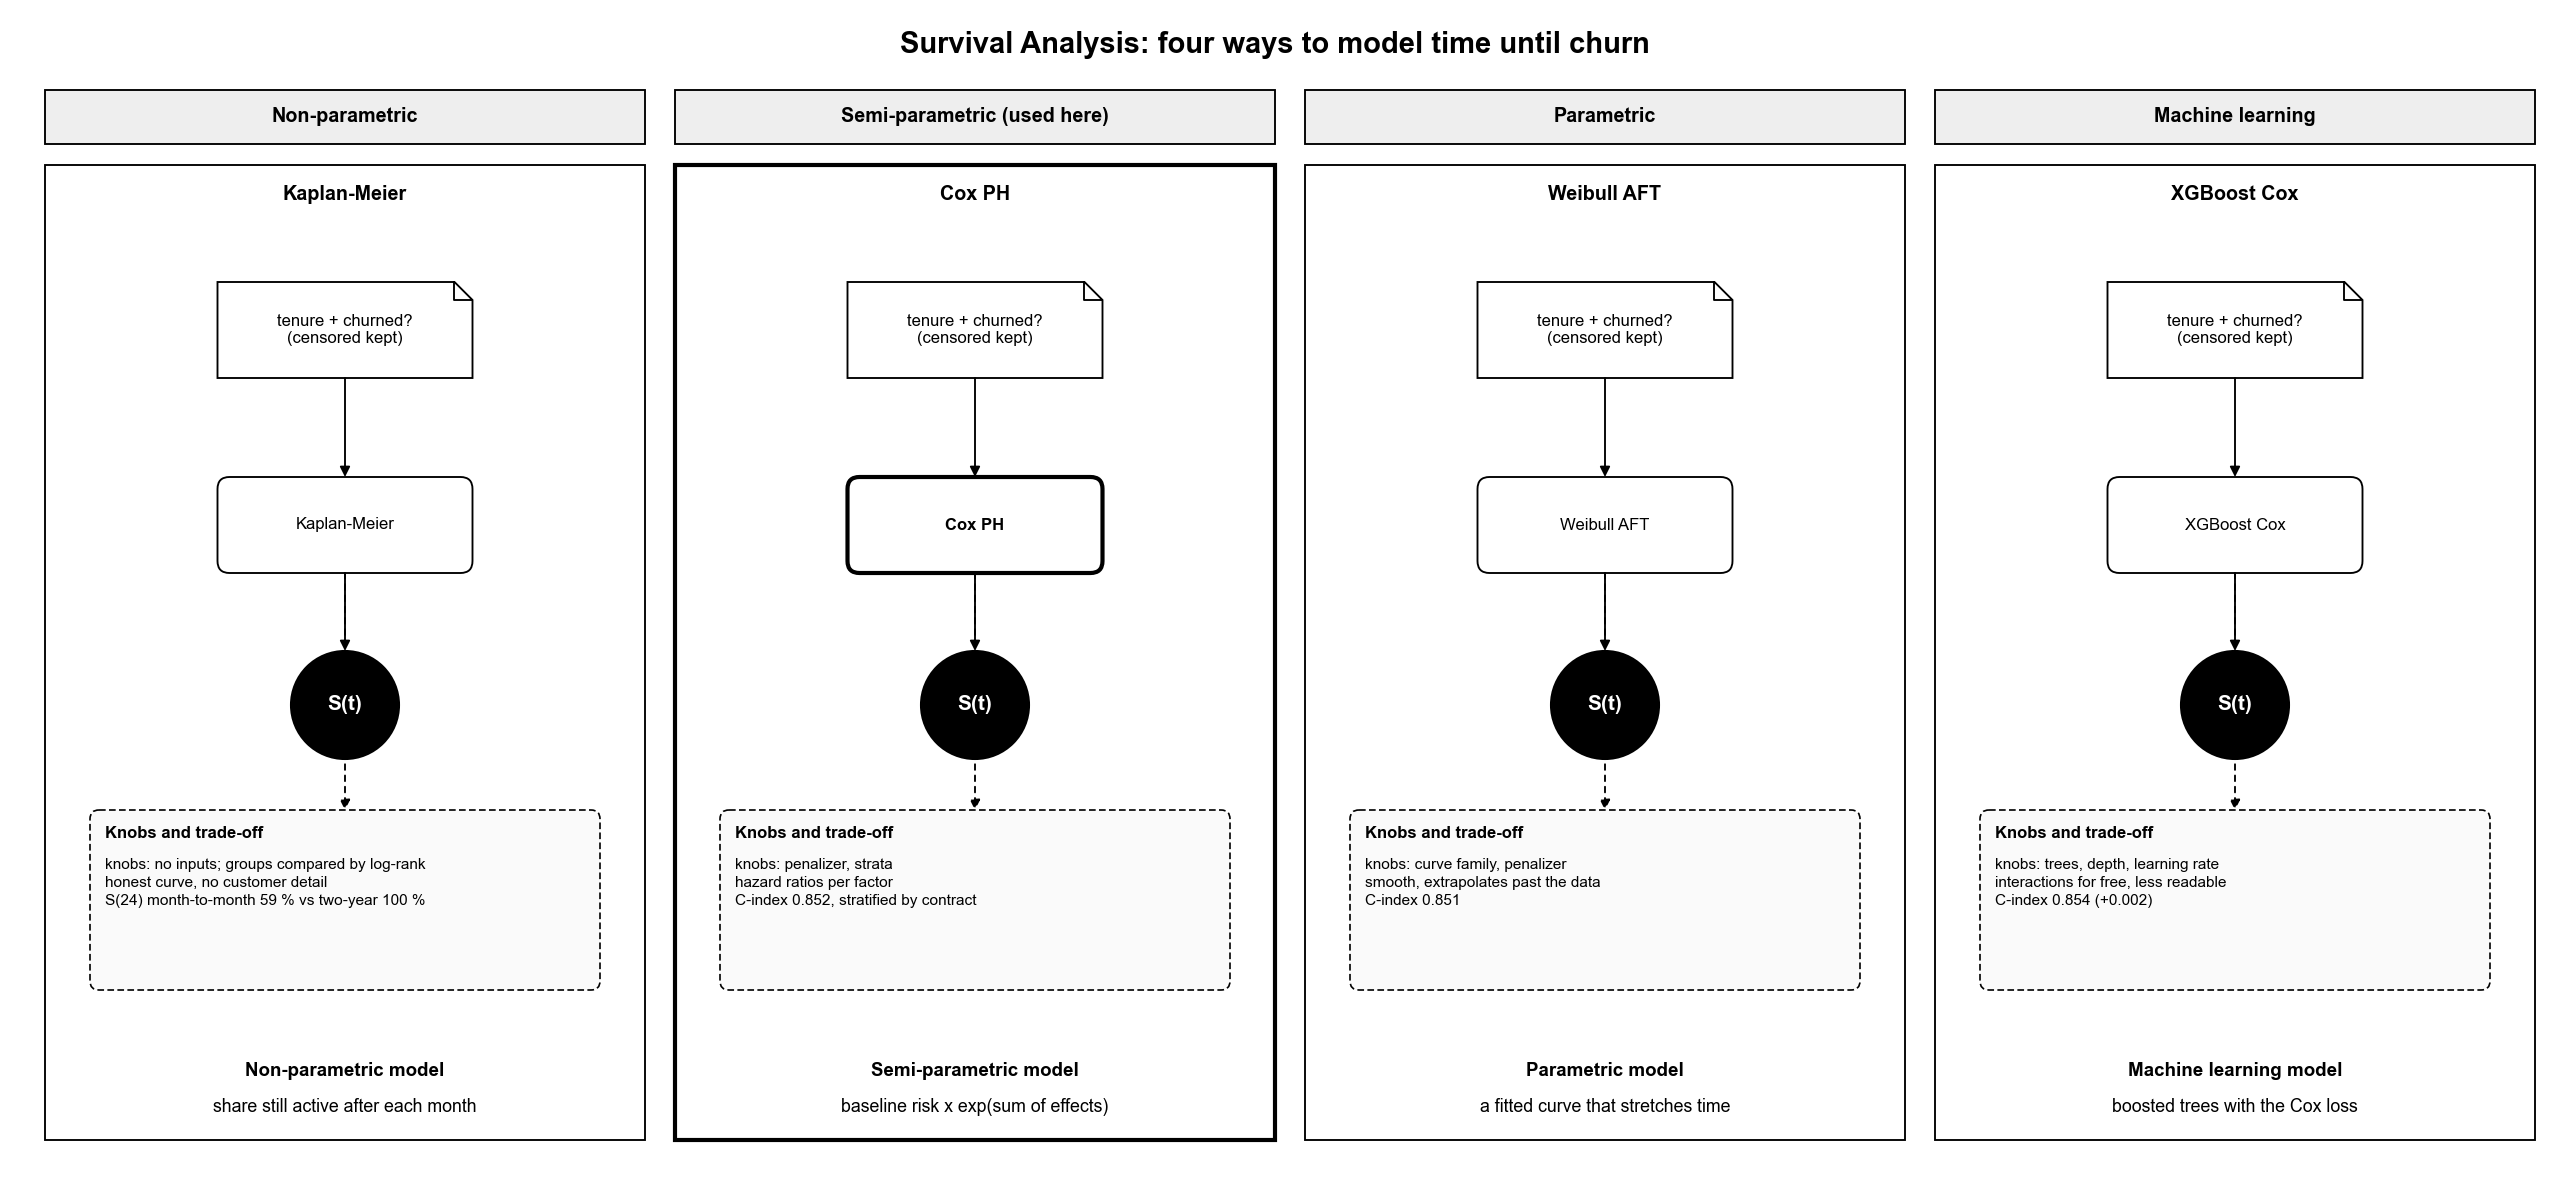

**Question:** Does a survival model beat a plain yes/no classifier, and does boosting beat Cox?

$$C = \frac{\#\{\text{pairs where the customer who left first got the higher risk}\}}{\#\{\text{comparable pairs}\}}$$
- 0.5 = random order, 1.0 = perfect; censored customers only count in pairs where the order is known
- **Weibull AFT** → a parametric curve that stretches or shrinks time; **XGBoost Cox** → boosted trees with the Cox loss; **logistic** → the usual churn yes/no model, its probability used as risk
- Analogy → a ranking of runners: only the order matters, not the exact finishing time

**Answer:** survival beats classification; boosting adds almost nothing.
- test C-index: XGBoost Cox 0.854, Cox 0.852, Weibull 0.851, logistic yes/no 0.805, monthly charge alone 0.508
- the gap holds for first-year customers (0.68 vs 0.64), the group a classifier mislabels as "loyal" because they have not had time to leave

In [ ]:
aft = WeibullAFTFitter(penalizer=PENALIZER).fit(train, duration_col='tenure', event_col='churn')
y_signed = np.where(train['churn'] == 1, train['tenure'], -train['tenure'])
xgb_cox = xgb.XGBRegressor(objective='survival:cox', n_estimators=400, learning_rate=0.03, max_depth=3, subsample=0.8,
                           colsample_bytree=0.8, random_state=SEED).fit(train[FEATURES], y_signed)
scaler = StandardScaler().fit(train[FEATURES])
logit = LogisticRegression(max_iter=2000).fit(scaler.transform(train[FEATURES]), train['churn'])

risk = {
    'Cox': cph.predict_partial_hazard(test[FEATURES]).to_numpy(),
    'Weibull AFT': -aft.predict_expectation(test[FEATURES]).to_numpy(),
    'XGBoost Cox': xgb_cox.predict(test[FEATURES]),
    'logistic (churn yes/no)': logit.predict_proba(scaler.transform(test[FEATURES]))[:, 1],
    'monthly charges only': test['monthly_charges_10usd'].to_numpy(),
}
cindex = pd.Series({name: concordance_index(test['tenure'], -r, test['churn']) for name, r in risk.items()}, name='test C-index')
new = test['tenure'] <= 12
cindex_new = pd.Series({name: concordance_index(test.loc[new, 'tenure'], -r[new.to_numpy()], test.loc[new, 'churn'])
                        for name, r in risk.items()}, name='C-index, first-year customers')

In [ ]:
display(pd.concat([cindex, cindex_new], axis=1).sort_values('test C-index', ascending=False).round(3))

# [10/13] Are the probabilities honest?

Compare predicted and observed churn at 6, 12 and 24 months by risk group → a calibrated model can be used for budgets

**Question:** When the model says "30 % will leave within a year", do 30 % leave?

- test customers are split into 5 groups by predicted risk; for each group, predicted $1 - \hat S(t)$ is compared with the Kaplan-Meier estimate of the same group
- points on the diagonal → honest probabilities
- Analogy → a weather forecaster whose "30 % rain" days are rainy 3 times in 10

**Answer:** yes, closely: across the 5 risk groups the predicted 12-month churn (0.5 %, 2 %, 10 %, 25 %, 50 %) tracks the observed (0 %, 1 %, 8 %, 29 %, 47 %), good enough to plan a budget.

In [ ]:
surv_test = cph.predict_survival_function(test[FEATURES], times=range(0, 73))
bins = pd.qcut(risk['Cox'], 5, labels=False)
calib = []
for h in HORIZONS:
    pred = 1 - surv_test.loc[h].to_numpy()
    for b in range(5):
        m = bins == b
        calib.append({'months': h, 'risk group': b + 1, 'predicted churn': pred[m].mean(),
                      'observed churn (KM)': 1 - km_at(test['tenure'][m], test['churn'][m], h)})
calib = pd.DataFrame(calib)

In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(18, 5))
for ax, h in zip(axes, HORIZONS):
    part = calib[calib['months'] == h]
    ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
    ax.plot(part['predicted churn'], part['observed churn (KM)'], marker='o', color='black')
    ax.set(title=f'Churn within {h} months', xlabel='predicted', ylabel='observed (Kaplan-Meier)', xlim=(0, 1), ylim=(0, 1))
fig.suptitle('Calibration of the Cox model on test customers (5 risk groups)', fontweight='bold')
fig.tight_layout()
save(fig, '05_calibration')
plt.show()
display(calib.pivot(index='risk group', columns='months', values=['predicted churn', 'observed churn (KM)']).round(3))

# [11/13] One customer at a time

Draw the predicted lifetime curve for typical customers (contract-stratified Cox from section 8: same ranking, honest long-tenure probabilities) → the same customer with a different contract tells the business story

In [ ]:
base = X_all.loc[train_idx].median().to_dict()
profiles = {
    'month-to-month, fiber, e-check': {**base, 'one_year_contract': 0, 'two_year_contract': 0, 'fiber_optic': 1, 'no_internet': 0,
                                      'pay_electronic_check': 1, 'pay_mailed_check': 0, 'pay_credit_card': 0, 'TechSupport': 0},
    'same, with tech support': {},
    'same, one-year contract': {},
    'two-year contract, DSL, card': {**base, 'one_year_contract': 0, 'two_year_contract': 1, 'fiber_optic': 0, 'no_internet': 0,
                                    'pay_electronic_check': 0, 'pay_mailed_check': 0, 'pay_credit_card': 1, 'TechSupport': 1},
}
profiles['same, with tech support'] = {**profiles['month-to-month, fiber, e-check'], 'TechSupport': 1}
profiles['same, one-year contract'] = {**profiles['month-to-month, fiber, e-check'], 'one_year_contract': 1}
P = pd.DataFrame(profiles).T[FEATURES]
curves = surv_at(cph_strat, to_strat(P), list(range(0, 73))).T
curves.loc[0] = 1.0                       # everyone is a customer at month 0 (the model starts at the first event time)
rmst_profiles = curves.loc[:RMST_MONTHS].apply(lambda s: np.trapz(s.to_numpy(), s.index.to_numpy()))

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
for (name, curve), color, ls in zip(curves.items(), ['red', '#808080', 'grey', 'black'], ['-', '--', ':', '-']):
    ax.plot(curve.index, curve, color=color, linestyle=ls, label=f'{name} · {rmst_profiles[name]:.1f} of {RMST_MONTHS} months')
ax.set(title=f'Predicted lifetime curves (label: expected months as a customer in the first {RMST_MONTHS})', xlabel='months', ylabel='S(t)', ylim=(0, 1.02))
ax.legend(fontsize=9)
save(fig, '06_profiles')
plt.show()
display(curves.loc[HORIZONS].T.round(3))

**Question:** What does one customer's curve say that a churn flag cannot?

$$\text{RMST}(\tau) = \int_0^{\tau} \hat S(t)\, dt$$
- **restricted mean survival time** → expected months as a customer within the next $\tau$ months; times the monthly charge = expected revenue
- the gap between two profiles = months gained by a change (contract, support) for an otherwise identical customer
- Analogy → not "will the battery die?" but "how many hours are left?"

**Answer:** how many months a change is worth. Out of the next 24 months, a month-to-month fiber customer paying by e-check is expected to stay 8.8; with tech support 11.9; on a one-year contract 22.8; a two-year DSL customer paying by card all 24. (Comparisons of otherwise identical customers, not proof that offering the contract causes the gain.)

# [12/13] Who to call first

Turn each active customer's curve into revenue at risk over the next year → rank by money, not only by probability

**Question:** If the team can call 10 % of active customers, who and what is at stake?

$$\text{revenue at risk}_i = m_i \left(12 - \int_{t_i}^{t_i + 12} \frac{\hat S(u)}{\hat S(t_i)}\, du\right)$$
- $t_i$ → months the customer has already stayed; $\hat S(u) / \hat S(t_i)$ → the **conditional** curve: chance to stay, given they are still here
- $m_i$ → monthly charge; the bracket = expected months lost in the next 12
- Analogy → triaging by the cost of the problem, not only by how likely it is

**Answer:** 516 calls cover 43 % of next year's revenue at risk.
- $305,872 of revenue is at risk over the next 12 months across 5,163 active customers
- ranking by money covers 43.4 % of it, ranking by probability only 39.3% → call by revenue at risk
- 81 % of the called are month-to-month, many long-standing fiber customers paying $75-105 a month

In [ ]:
active = df[df['churn'] == 0]
grid = np.arange(0, 85)
S_active = surv_at(cph_strat, to_strat(X_all.loc[active.index]), list(grid)).T
lost, p12 = [], []
for cid, t0 in zip(active.index, active['tenure']):
    s = S_active[cid].to_numpy()
    cond = s[t0:t0 + 13] / max(s[t0], 1e-9)
    lost.append(12 - np.trapz(cond))
    p12.append(1 - cond[-1])
calls = active.assign(p_leave_12m=p12, months_lost=lost, revenue_at_risk=np.array(lost) * active['MonthlyCharges'])
n_call = int(len(calls) * CALL_SHARE)
by_money = calls.nlargest(n_call, 'revenue_at_risk')
by_prob = calls.nlargest(n_call, 'p_leave_12m')

In [ ]:
show_block('Outputs', {'active customers': f'{len(calls):,}', 'customers called': f'{n_call:,}',
                       'revenue at risk, next 12 months (all)': f'${calls["revenue_at_risk"].sum():,.0f}',
                       'share captured by "call by money"': f'{by_money["revenue_at_risk"].sum() / calls["revenue_at_risk"].sum():.1%}',
                       'share captured by "call by probability"': f'{by_prob["revenue_at_risk"].sum() / calls["revenue_at_risk"].sum():.1%}',
                       'month-to-month among the called': f'{(by_money["Contract"] == "Month-to-month").mean():.1%}'})
display(by_money[['tenure', 'Contract', 'InternetService', 'PaymentMethod', 'MonthlyCharges', 'p_leave_12m', 'revenue_at_risk']].head(8).round(2))

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = calls.sort_values('revenue_at_risk', ascending=False)['revenue_at_risk'].cumsum() / calls['revenue_at_risk'].sum()
ax.plot(np.arange(1, len(order) + 1) / len(order), order.to_numpy(), color='black', label='call by revenue at risk')
order_p = calls.sort_values('p_leave_12m', ascending=False)['revenue_at_risk'].cumsum() / calls['revenue_at_risk'].sum()
ax.plot(np.arange(1, len(order_p) + 1) / len(order_p), order_p.to_numpy(), color='grey', linestyle='--', label='call by probability')
ax.axvline(CALL_SHARE, color='red', linestyle=':')
ax.set(title='Share of next-year revenue at risk covered by the call list', xlabel='share of active customers called', ylabel='revenue at risk covered')
ax.legend()
save(fig, '07_call_list')
plt.show()

# [13/13] Save and app

Save the Cox model and the encoding → the Gradio app draws any customer's curve and revenue at risk

In [ ]:
"""Optional · SAVE_MODEL writes the model for app.py; LAUNCH_APP starts the explorer (Kaggle prints a public link)."""
if SAVE_MODEL:
    import joblib
    joblib.dump({'cph_strat': cph_strat, 'features': FEATURES, 'strat_inputs': STRAT_INPUTS, 'base': base,
                 'rmst_months': RMST_MONTHS}, MODEL_FILE)
    print(f'Saved → {MODEL_FILE}')
else:
    print(f'Preview · would save → {MODEL_FILE} · nothing written (SAVE_MODEL = False)')

if LAUNCH_APP:
    import gradio as gr

    def explore(contract, internet, payment, tech, security, monthly, tenure_now):
        row = {**base, 'one_year_contract': int(contract == 'One year'), 'two_year_contract': int(contract == 'Two year'),
               'fiber_optic': int(internet == 'Fiber optic'), 'no_internet': int(internet == 'No'),
               'pay_electronic_check': int(payment == 'Electronic check'), 'pay_mailed_check': int(payment == 'Mailed check'),
               'pay_credit_card': int(payment == 'Credit card (automatic)'), 'TechSupport': int(tech), 'OnlineSecurity': int(security),
               'monthly_charges_10usd': monthly / 10}
        s = surv_at(cph_strat, to_strat(pd.DataFrame([row])[FEATURES]), list(grid)).iloc[0].to_numpy()
        cond = s[tenure_now:tenure_now + 25] / s[tenure_now]
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(range(25), cond, color='black')
        ax.set(xlabel='months from now', ylabel='P(still a customer)', ylim=(0, 1.02))
        return {f'stay {h} months': float(cond[h]) for h in (6, 12, 24)}, fig

    gr.Interface(explore, [gr.Dropdown(['Month-to-month', 'One year', 'Two year'], value='Month-to-month', label='Contract'),
                           gr.Dropdown(['DSL', 'Fiber optic', 'No'], value='Fiber optic', label='Internet'),
                           gr.Dropdown(['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)'],
                                       value='Electronic check', label='Payment'),
                           gr.Checkbox(label='Tech support'), gr.Checkbox(label='Online security'),
                           gr.Slider(18, 120, value=80, label='Monthly charge ($)'), gr.Slider(1, 48, value=3, step=1, label='Months so far')],
                 [gr.Label(label='Chance to stay'), gr.Plot()], title='Churn explorer').launch(share=True)
else:
    print('Preview · app not started (LAUNCH_APP = False)')

**Summary**

- **Censoring** → 73 % of customers have not left yet; survival analysis uses them, simple averages do not
- **When** → risk is highest in the first months (1.5 % a month, 0.4 % by month 36)
- **Why** → contract is the biggest lever (two-year: 12× less risk), then payment method and support services
- **Model** → Cox ranks customers far better than a yes/no classifier (C-index 0.85 vs 0.81) with honest probabilities
- **Action** → call the top 10 % by revenue at risk: 43 % of next year's money at stake